# Notebook 2 — Analisis Suhu Permukaan Laut (SST) dan Deteksi Marine Heatwave (MHW) di Perairan NTT

**Proyek:** Analisis Dinamika Oseanografi dan Kejadian Marine Heatwave di Perairan Nusa Tenggara Timur  
**Metodologi:** Hobday et al. (2016, 2018)  
**Periode Analisis:** 2000–2020 (21 tahun)  
**Wilayah:** Perairan NTT (Bounding Box: 117.5°–127.5°BT, -13.0°–-7.0°LS)  

---

## Ringkasan Tujuan
1. Menganalisis karakteristik temporal dan spasial Suhu Permukaan Laut (*Sea Surface Temperature* / SST) di perairan NTT.
2. Membangun klimatologi harian dan ambang batas (*threshold*) persentil ke-90 musiman menggunakan jendela geser 31 hari.
3. Mengidentifikasi dan mengkatalogkan kejadian *Marine Heatwave* (MHW) berdasarkan kriteria Hobday et al. (2016): durasi $\ge 5$ hari berturut-turut, penggabungan jeda $\le 2$ hari.
4. Menghitung metrik keparahan MHW: durasi, intensitas maksimum ($i_{max}$), intensitas rata-rata ($i_{mean}$), intensitas kumulatif ($i_{cum}$), dan kategorisasi keparahan (Kategori I–IV).
5. Menganalisis variasi tahunan dan sebaran spasial MHW di seluruh grid perairan NTT.

> **Catatan Metodologis & Kepatuhan Prinsip:**
> - **Tidak Menggunakan Indeks ONI:** Analisis ini berfokus murni pada observasi termal in-situ/satelit di NTT tanpa mengandalkan proksi ONI (*Oceanic Niño Index*).
> - **Periode Referensi 21 Tahun:** Periode baseline 2000–2020 mencakup 21 tahun data satelit resolusi tinggi OISST v2.1. Keterbatasan ini dinyatakan secara transparan (bukan klimatologi standar WMO 30 tahun).

---
## 1. Konfigurasi dan Impor Pustaka

In [1]:
import sys
import os
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from scipy.ndimage import uniform_filter1d

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Tambahkan path folder config
notebook_dir = Path(os.path.abspath(''))
project_root = notebook_dir.parent if notebook_dir.name == 'notebooks' else notebook_dir
sys.path.insert(0, str(project_root / 'config'))

import project_config as cfg

print("=" * 60)
print("KONFIGURASI NOTEBOOK 2 — ANALISIS SST & DETEKSI MHW")
print("=" * 60)
print(f"Project Root     : {cfg.PROJECT_ROOT}")
print(f"Input SST        : {cfg.SST_MERGED_OUTPUT}")
print(f"Periode Baseline : {cfg.MHW_BASELINE_START}–{cfg.MHW_BASELINE_END} (21 tahun)")
print(f"Ambang MHW       : Persentil ke-{cfg.MHW_PERCENTILE}")
print(f"Durasi Minimum   : {cfg.MHW_MIN_DURATION_DAYS} hari berturut-turut")
print(f"Jendela Smoothing: {cfg.MHW_SMOOTHING_WINDOW} hari")
print(f"Folder Output    : {cfg.PROCESSED_DIR}")

KONFIGURASI NOTEBOOK 2 — ANALISIS SST & DETEKSI MHW
Project Root     : G:\My Drive\KLIMTROP\PBL
Input SST        : G:\My Drive\KLIMTROP\PBL\data\processed\sst_daily_2000_2020_ntt.nc
Periode Baseline : 2000–2020 (21 tahun)
Ambang MHW       : Persentil ke-90
Durasi Minimum   : 5 hari berturut-turut
Jendela Smoothing: 31 hari
Folder Output    : G:\My Drive\KLIMTROP\PBL\data\processed


---
## 2. Pemuatan dan Verifikasi Dataset SST Gabungan

Memuat dataset SST harian yang telah diproses dan diverifikasi dari Notebook 1 (`sst_daily_2000_2020_ntt.nc`).

In [2]:
# Buka dataset SST
sst_file = cfg.SST_MERGED_OUTPUT

if not sst_file.exists():
    raise FileNotFoundError(
        f"File SST gabungan tidak ditemukan di: {sst_file}\n"
        "Jalankan Notebook 1 terlebih dahulu untuk menghasilkan file ini."
    )

ds_sst = xr.open_dataset(sst_file)
print(f"Dataset SST berhasil dimuat:")
print(f"  Dimensi: {dict(ds_sst.sizes)}")
print(f"  Variabel: {list(ds_sst.data_vars)}")
print(f"  Rentang Waktu: {str(ds_sst.time.values[0])[:10]} s.d. {str(ds_sst.time.values[-1])[:10]} ({len(ds_sst.time)} hari)")
print(f"  Grid Spasial: {len(ds_sst.lat)} lat x {len(ds_sst.lon)} lon (0.25° x 0.25°)")
print(f"  Lat range: {float(ds_sst.lat.min()):.3f}° s.d. {float(ds_sst.lat.max()):.3f}°")
print(f"  Lon range: {float(ds_sst.lon.min()):.3f}° s.d. {float(ds_sst.lon.max()):.3f}°")

# Hitung deret waktu rata-rata spasial regional NTT
# Catat: area perairan (abaikan darat/NaN)
sst_regional_mean = ds_sst['sst'].mean(dim=['lat', 'lon'], skipna=True)
df_ts = pd.DataFrame({
    'time': pd.to_datetime(ds_sst.time.values),
    'sst': sst_regional_mean.values
}).set_index('time')

print("\nRingkasan Statistik SST Regional:")
print(df_ts['sst'].describe().round(3))

Dataset SST berhasil dimuat:
  Dimensi: {'time': 7671, 'lat': 24, 'lon': 40}
  Variabel: ['sst']
  Rentang Waktu: 2000-01-01 s.d. 2020-12-31 (7671 hari)
  Grid Spasial: 24 lat x 40 lon (0.25° x 0.25°)
  Lat range: -12.875° s.d. -7.125°
  Lon range: 117.625° s.d. 127.375°



Ringkasan Statistik SST Regional:
count    7671.000
mean       28.631
std         1.181
min        25.084
25%        27.741
50%        28.846
75%        29.541
max        31.641
Name: sst, dtype: float64


---
## 3. Karakteristik Temporal dan Siklus Musiman SST NTT

Analisis variasi musiman SST regional NTT untuk memahami pola siklus tahunan (monsun barat vs monsun timur).

Klimatologi Bulanan SST Regional NTT (°C):
          mean   std        min        max    p90
Jan  29.320000  0.46  28.330000  30.940001  29.95
Feb  29.180000  0.62  27.980000  31.160000  29.98
Mar  29.320000  0.64  28.000000  31.290001  30.08
Apr  29.480000  0.57  27.900000  30.920000  30.25
Mei  28.770000  0.51  27.340000  30.160000  29.40
Jun  27.879999  0.58  26.559999  29.510000  28.56
Jul  27.080000  0.58  25.809999  29.049999  27.83
Agu  26.760000  0.56  25.080000  28.150000  27.51
Sep  27.500000  0.63  25.870001  29.480000  28.35
Okt  28.610001  0.60  26.980000  30.059999  29.37
Nov  29.760000  0.44  28.639999  30.959999  30.34
Des  29.959999  0.59  27.969999  31.639999  30.64


C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_37984\3209013949.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(monthly_data, labels=month_names, patch_artist=True,


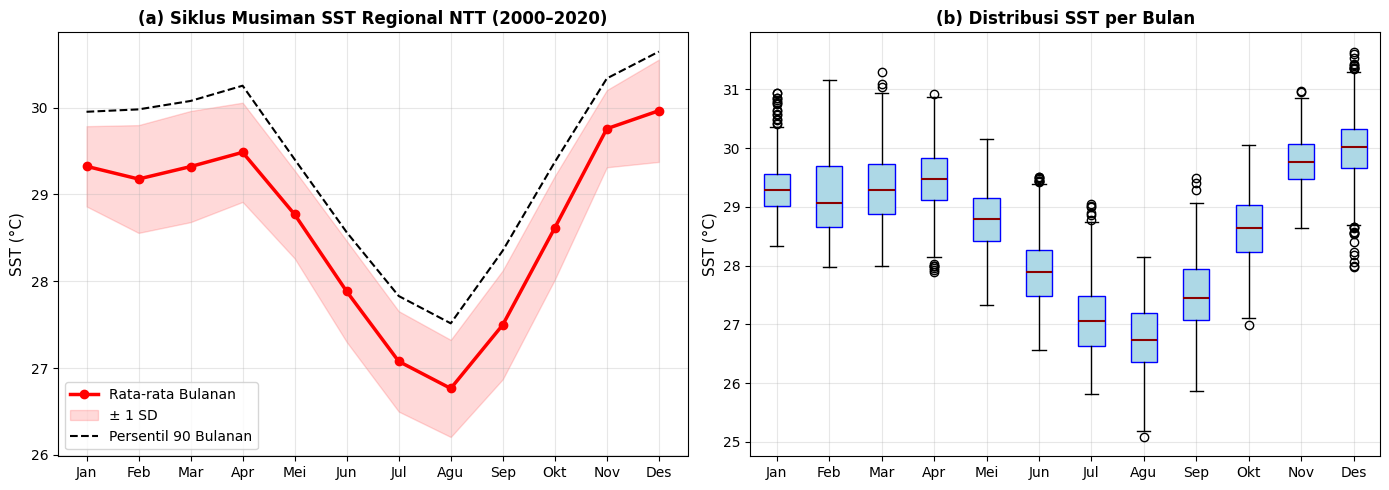

In [3]:
# Analisis siklus musiman bulanan
df_ts['year'] = df_ts.index.year
df_ts['month'] = df_ts.index.month
df_ts['dayofyear'] = df_ts.index.dayofyear

monthly_clim = df_ts.groupby('month')['sst'].agg(['mean', 'std', 'min', 'max', lambda x: x.quantile(0.9)])
monthly_clim.columns = ['mean', 'std', 'min', 'max', 'p90']

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
monthly_clim.index = month_names

print("Klimatologi Bulanan SST Regional NTT (°C):")
print(monthly_clim.round(2))

# Visualisasi Siklus Musiman
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Rata-rata bulanan dan pita standar deviasi
axes[0].plot(range(1, 13), monthly_clim['mean'], 'ro-', lw=2.5, label='Rata-rata Bulanan')
axes[0].fill_between(range(1, 13), monthly_clim['mean'] - monthly_clim['std'],
                     monthly_clim['mean'] + monthly_clim['std'], color='red', alpha=0.15, label='± 1 SD')
axes[0].plot(range(1, 13), monthly_clim['p90'], 'k--', lw=1.5, label='Persentil 90 Bulanan')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_names)
axes[0].set_ylabel('SST (°C)', fontsize=11)
axes[0].set_title('(a) Siklus Musiman SST Regional NTT (2000–2020)', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='lower left')

# Plot 2: Boxplot bulanan
monthly_data = [df_ts[df_ts['month'] == m]['sst'].dropna() for m in range(1, 13)]
axes[1].boxplot(monthly_data, labels=month_names, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='darkred', lw=1.5))
axes[1].set_ylabel('SST (°C)', fontsize=11)
axes[1].set_title('(b) Distribusi SST per Bulan', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb2_sst_seasonal_cycle.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 4. Pola Spasial SST di Perairan NTT

Peta spasial rata-rata tahunan dan musiman di perairan NTT:
- Monsun Barat (DJF: Desember, Januari, Februari)
- Peralihan 1 (MAM: Maret, April, Mei)
- Monsun Timur (JJA: Juni, Juli, Agustus - periode upwelling di Laut Sawu dan selatan Timor)
- Peralihan 2 (SON: September, Oktober, November)

C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_37984\3257509395.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 0.95])


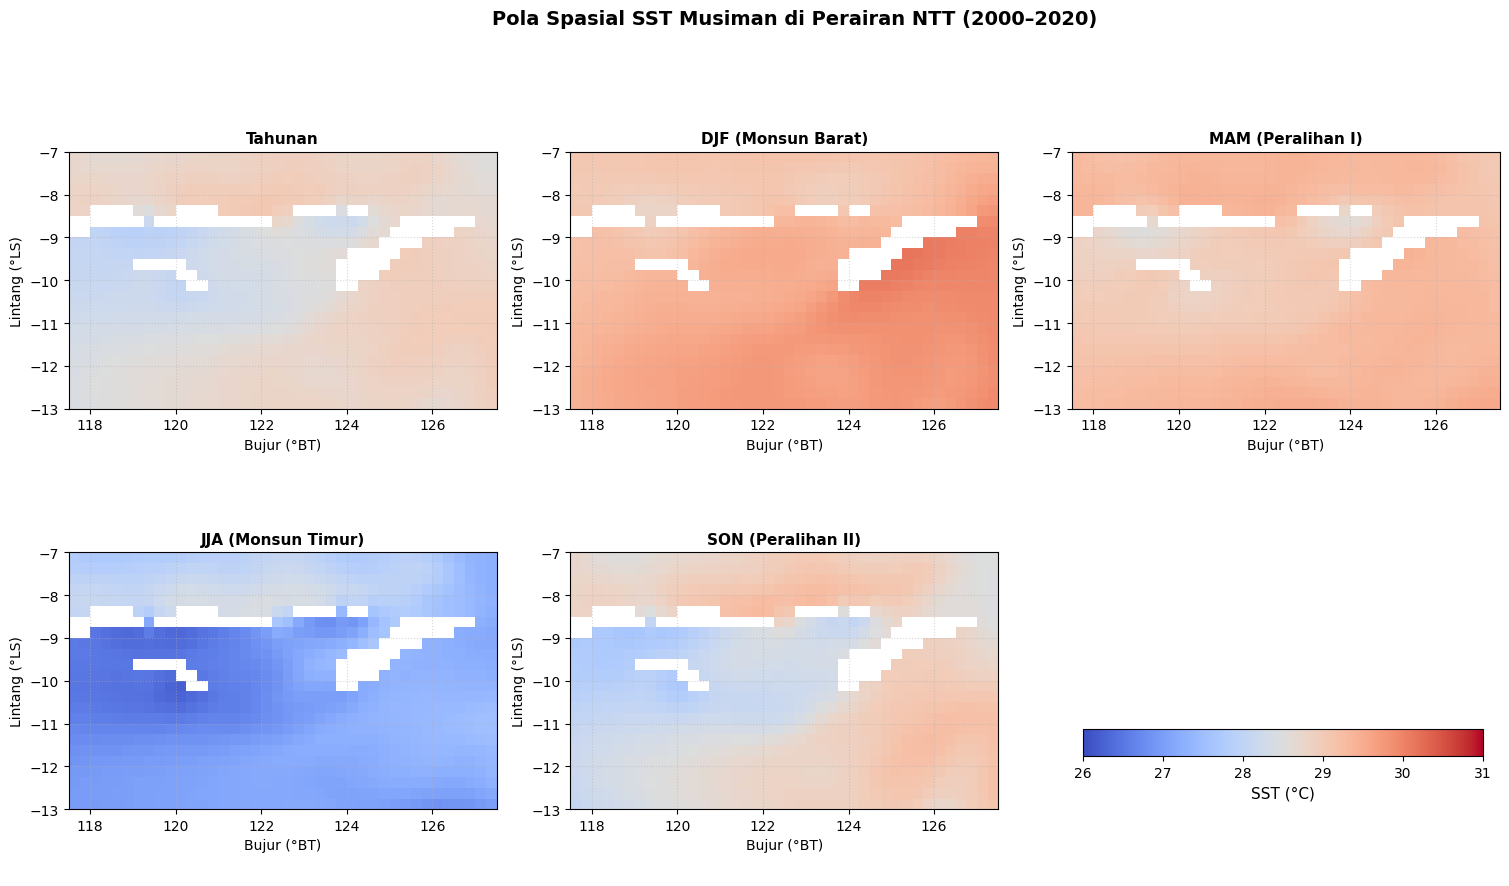

In [4]:
# Hitung rata-rata spasial musiman
seasons = {
    'Tahunan': ds_sst['sst'].mean(dim='time'),
    'DJF (Monsun Barat)': ds_sst['sst'].sel(time=ds_sst.time.dt.month.isin([12, 1, 2])).mean(dim='time'),
    'MAM (Peralihan I)': ds_sst['sst'].sel(time=ds_sst.time.dt.month.isin([3, 4, 5])).mean(dim='time'),
    'JJA (Monsun Timur)': ds_sst['sst'].sel(time=ds_sst.time.dt.month.isin([6, 7, 8])).mean(dim='time'),
    'SON (Peralihan II)': ds_sst['sst'].sel(time=ds_sst.time.dt.month.isin([9, 10, 11])).mean(dim='time')
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

vmin_sst = 26.0
vmax_sst = 31.0

for i, (title, sst_map) in enumerate(seasons.items()):
    ax = axes[i]
    im = ax.pcolormesh(ds_sst.lon, ds_sst.lat, sst_map,
                       cmap=cfg.COLORMAP_SST, vmin=vmin_sst, vmax=vmax_sst, shading='auto')
    ax.set_title(f"{title}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Bujur (°BT)')
    ax.set_ylabel('Lintang (°LS)')
    ax.set_aspect('equal')
    ax.grid(True, linestyle=':', alpha=0.5)

# Matikan sumbu ke-6 yang kosong
axes[5].axis('off')

# Colorbar terpusat
cbar_ax = fig.add_axes([0.68, 0.15, 0.25, 0.03])
cb = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cb.set_label('SST (°C)', fontsize=11)

plt.suptitle('Pola Spasial SST Musiman di Perairan NTT (2000–2020)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 0.95, 0.95])
fig.savefig(cfg.FIGURES_DIR / "nb2_sst_spatial_patterns.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 5. Implementasi Algoritma Deteksi MHW (Hobday et al., 2016)

### Tahapan Perhitungan:
1. **Ekstraksi Hari dalam Tahun (*Day-of-Year* / DOY):** Tanggal kabisat (29 Februari) diselaraskan ke hari ke-60. Rentang DOY: $1 \le d \le 366$.
2. **Klimatologi Musiman ($T_{clim}(d)$):** Untuk setiap DOY $d$, ambil semua observasi dalam jendela $d \pm 15$ hari (total 31 hari) di seluruh 21 tahun baseline (2000–2020), lalu hitung nilai rata-rata.
3. **Ambang Batas Persentil ke-90 ($T_{thresh}(d)$):** Hitung persentil ke-90 dari observasi pada jendela 31 hari yang sama.
4. **Penyelarasan Sirkular (*Circular Smoothing*):** Terapkan filter jendela geser 31 hari secara sirkular (memastikan kontinuitas antara 31 Desember dan 1 Januari).
5. **Identifikasi Kejadian MHW:**
   - Suhu melebihi ambang batas: $T(t) > T_{thresh}(t)$.
   - Durasi berturut-turut $\ge 5$ hari.
   - Penggabungan kejadian (*joining*): jika dua periode dipisahkan oleh jeda $\le 2$ hari dan suhu tetap berada di atas nilai klimatologi ($T(t) > T_{clim}(t)$), kedua periode digabung menjadi satu kejadian.
6. **Metrik Karakteristik MHW:**
   - **Durasi ($D$):** Jumlah hari sejak mulai hingga selesai.
   - **Intensitas Maksimum ($i_{max}$):** $\max(T(t) - T_{clim}(t))$ selama kejadian (°C).
   - **Intensitas Rata-rata ($i_{mean}$):** Rata-rata anomali di atas klimatologi (°C).
   - **Intensitas Kumulatif ($i_{cum}$):** $\sum (T(t) - T_{clim}(t))$ (°C·hari).
   - **Kategorisasi (Hobday et al., 2018):** Berdasarkan kelipatan $\Delta T = T_{thresh} - T_{clim}$:
     - Kategori I (Moderat): $1 \times \Delta T \le i_{max} < 2 \times \Delta T$
     - Kategori II (Kuat): $2 \times \Delta T \le i_{max} < 3 \times \Delta T$
     - Kategori III (Parah): $3 \times \Delta T \le i_{max} < 4 \times \Delta T$
     - Kategori IV (Ekstrem): $i_{max} \ge 4 \times \Delta T$

In [5]:
def compute_climatology_and_threshold(time_index, sst_series, window_half=15, pct=90, smooth_window=31):
    """
    Menghitung klimatologi harian dan ambang persentil ke-90 musiman
    sesuai standar Hobday et al. (2016).
    """
    # Buat day of year (1-366)
    doy = time_index.dayofyear.values
    sst = np.asarray(sst_series)
    
    clim_raw = np.zeros(366)
    thresh_raw = np.zeros(366)
    
    for d in range(1, 367):
        # Cari semua indeks dalam d +/- window_half secara sirkular
        d_min = (d - window_half - 1) % 366 + 1
        d_max = (d + window_half - 1) % 366 + 1
        
        if d_min <= d_max:
            mask = (doy >= d_min) & (doy <= d_max)
        else:
            mask = (doy >= d_min) | (doy <= d_max)
            
        vals = sst[mask]
        vals = vals[~np.isnan(vals)]
        
        if len(vals) > 0:
            clim_raw[d-1] = np.mean(vals)
            thresh_raw[d-1] = np.percentile(vals, pct)
        else:
            clim_raw[d-1] = np.nan
            thresh_raw[d-1] = np.nan
            
    # Smoothing sirkular menggunakan uniform_filter1d dengan mode='wrap'
    clim_smoothed = uniform_filter1d(clim_raw, size=smooth_window, mode='wrap')
    thresh_smoothed = uniform_filter1d(thresh_raw, size=smooth_window, mode='wrap')
    
    return clim_smoothed, thresh_smoothed

def detect_mhw_events(time_index, sst_series, clim_doy, thresh_doy, min_duration=5, max_gap=2):
    """
    Mendeteksi kejadian Marine Heatwave (MHW) berdasarkan kriteria durasi dan gap.
    """
    doy = time_index.dayofyear.values
    sst = np.asarray(sst_series)
    
    # Petakan klimatologi dan threshold ke deret waktu penuh
    clim_ts = clim_doy[doy - 1]
    thresh_ts = thresh_doy[doy - 1]
    
    is_above = sst > thresh_ts
    
    # Identifikasi blok berturut-turut di atas ambang batas
    events = []
    in_event = False
    start_idx = None
    
    for i in range(len(sst)):
        if is_above[i] and not in_event:
            in_event = True
            start_idx = i
        elif not is_above[i] and in_event:
            in_event = False
            events.append((start_idx, i - 1))
    if in_event:
        events.append((start_idx, len(sst) - 1))
        
    # Penggabungan kejadian dengan jeda <= max_gap hari
    # jika suhu selama jeda tetap di atas klimatologi
    merged_events = []
    if events:
        curr_start, curr_end = events[0]
        for next_start, next_end in events[1:]:
            gap = next_start - curr_end - 1
            # Cek apakah gap <= max_gap dan SST selama jeda > klimatologi
            if gap <= max_gap and np.all(sst[curr_end+1:next_start] > clim_ts[curr_end+1:next_start]):
                # Gabungkan
                curr_end = next_end
            else:
                merged_events.append((curr_start, curr_end))
                curr_start, curr_end = next_start, next_end
        merged_events.append((curr_start, curr_end))
        
    # Saring kejadian dengan durasi >= min_duration
    final_events = []
    for s_idx, e_idx in merged_events:
        duration = e_idx - s_idx + 1
        if duration >= min_duration:
            ev_sst = sst[s_idx:e_idx+1]
            ev_clim = clim_ts[s_idx:e_idx+1]
            ev_thresh = thresh_ts[s_idx:e_idx+1]
            anom = ev_sst - ev_clim
            delta_thresh = ev_thresh - ev_clim
            
            i_max = np.max(anom)
            peak_idx = s_idx + np.argmax(anom)
            i_mean = np.mean(anom)
            i_cum = np.sum(anom)
            
            # Kategori Hobday et al. (2018) pada saat puncak
            ratio = i_max / delta_thresh[np.argmax(anom)]
            if ratio < 2.0:
                cat = "I (Moderat)"
            elif ratio < 3.0:
                cat = "II (Kuat)"
            elif ratio < 4.0:
                cat = "III (Parah)"
            else:
                cat = "IV (Ekstrem)"
                
            final_events.append({
                'event_id': len(final_events) + 1,
                'start_date': time_index[s_idx].strftime('%Y-%m-%d'),
                'end_date': time_index[e_idx].strftime('%Y-%m-%d'),
                'peak_date': time_index[peak_idx].strftime('%Y-%m-%d'),
                'duration_days': int(duration),
                'i_max': round(float(i_max), 3),
                'i_mean': round(float(i_mean), 3),
                'i_cum': round(float(i_cum), 3),
                'category': cat,
                'start_idx': s_idx,
                'end_idx': e_idx
            })
            
    df_events = pd.DataFrame(final_events)
    return df_events, clim_ts, thresh_ts

print("Fungsi deteksi MHW Hobday et al. (2016) siap.")

Fungsi deteksi MHW Hobday et al. (2016) siap.


---
## 6. Perhitungan Klimatologi dan Ambang Batas SST Regional NTT

In [6]:
# Jalankan deteksi MHW untuk rata-rata spasial regional NTT
clim_doy, thresh_doy = compute_climatology_and_threshold(
    df_ts.index, df_ts['sst'].values,
    window_half=15, pct=cfg.MHW_PERCENTILE, smooth_window=cfg.MHW_SMOOTHING_WINDOW
)

df_events, clim_ts, thresh_ts = detect_mhw_events(
    df_ts.index, df_ts['sst'].values,
    clim_doy, thresh_doy,
    min_duration=cfg.MHW_MIN_DURATION_DAYS, max_gap=2
)

# Simpan deret klimatologi & threshold ke dataframe
df_ts['clim'] = clim_ts
df_ts['thresh'] = thresh_ts
df_ts['anom'] = df_ts['sst'] - df_ts['clim']
df_ts['is_mhw_day'] = False
for _, ev in df_events.iterrows():
    df_ts.loc[ev['start_date']:ev['end_date'], 'is_mhw_day'] = True

print(f"Hasil Deteksi MHW Regional NTT (2000–2020):")
print(f"  Total Kejadian MHW Teridentifikasi : {len(df_events)}")
print(f"  Total Hari dalam Kondisi MHW       : {df_ts['is_mhw_day'].sum()} hari "
      f"({100 * df_ts['is_mhw_day'].sum() / len(df_ts):.2f}% dari seluruh periode)")
print(f"  Rata-rata Durasi per Kejadian      : {df_events['duration_days'].mean():.1f} hari")
print(f"  Durasi Terpanjang                  : {df_events['duration_days'].max()} hari")
print(f"  Intensitas Maksimum Tertinggi      : {df_events['i_max'].max():.2f} °C")
print(f"  Intensitas Kumulatif Tertinggi     : {df_events['i_cum'].max():.2f} °C·hari")

Hasil Deteksi MHW Regional NTT (2000–2020):
  Total Kejadian MHW Teridentifikasi : 43
  Total Hari dalam Kondisi MHW       : 589 hari (7.68% dari seluruh periode)
  Rata-rata Durasi per Kejadian      : 13.7 hari
  Durasi Terpanjang                  : 87 hari
  Intensitas Maksimum Tertinggi      : 2.06 °C
  Intensitas Kumulatif Tertinggi     : 97.72 °C·hari


---
## 7. Katalog dan Ringkasan Kejadian MHW Utama

Tabel 10 kejadian MHW terkuat berdasarkan intensitas kumulatif ($i_{cum}$) dan intensitas maksimum ($i_{max}$).

In [7]:
# Top 10 MHW berdasarkan intensitas kumulatif
top_events_icum = df_events.sort_values('i_cum', ascending=False).head(10)
print("Top 10 Kejadian MHW Berdasarkan Intensitas Kumulatif:")
cols_display = ['event_id', 'start_date', 'end_date', 'duration_days', 'i_max', 'i_mean', 'i_cum', 'category']
print(top_events_icum[cols_display].to_string(index=False))

# Ringkasan per Kategori
cat_summary = df_events.groupby('category').agg(
    jumlah=('event_id', 'count'),
    durasi_rata_rata=('duration_days', 'mean'),
    i_max_rata_rata=('i_max', 'mean'),
    i_cum_rata_rata=('i_cum', 'mean')
).round(2)
print("\nRingkasan per Kategori Keparahan MHW:")
print(cat_summary)

# Simpan tabel kejadian MHW lengkap ke CSV
df_events_export = df_events.drop(columns=['start_idx', 'end_idx'])
df_events_export.to_csv(cfg.MHW_EVENTS_OUTPUT, index=False)
df_events_export.to_csv(cfg.TABLES_DIR / "nb2_mhw_events_all.csv", index=False)
top_events_icum[cols_display].to_csv(cfg.TABLES_DIR / "nb2_mhw_top10_events.csv", index=False)
print(f"\n✅ Katalog kejadian MHW disimpan: {cfg.MHW_EVENTS_OUTPUT}")

Top 10 Kejadian MHW Berdasarkan Intensitas Kumulatif:
 event_id start_date   end_date  duration_days  i_max  i_mean  i_cum    category
       28 2016-05-23 2016-08-17             87  1.851   1.123 97.718   II (Kuat)
       26 2016-02-15 2016-04-25             71  1.785   1.213 86.105   II (Kuat)
       36 2019-12-06 2020-01-04             30  1.605   1.152 34.549   II (Kuat)
       15 2010-03-23 2010-04-21             30  1.445   1.081 32.442 I (Moderat)
        4 2005-02-15 2005-03-05             19  2.064   1.298 24.660   II (Kuat)
       25 2016-01-10 2016-01-29             20  1.656   1.158 23.159   II (Kuat)
        2 2002-12-14 2002-12-29             16  1.725   1.390 22.236   II (Kuat)
       30 2016-09-20 2016-10-06             17  1.477   1.218 20.704 I (Moderat)
       35 2018-04-04 2018-04-19             16  1.348   1.119 17.902 I (Moderat)
       16 2010-05-27 2010-06-15             20  1.060   0.875 17.497 I (Moderat)

Ringkasan per Kategori Keparahan MHW:
             jum

---
## 8. Visualisasi Kurva Klimatologi dan Garis Waktu MHW

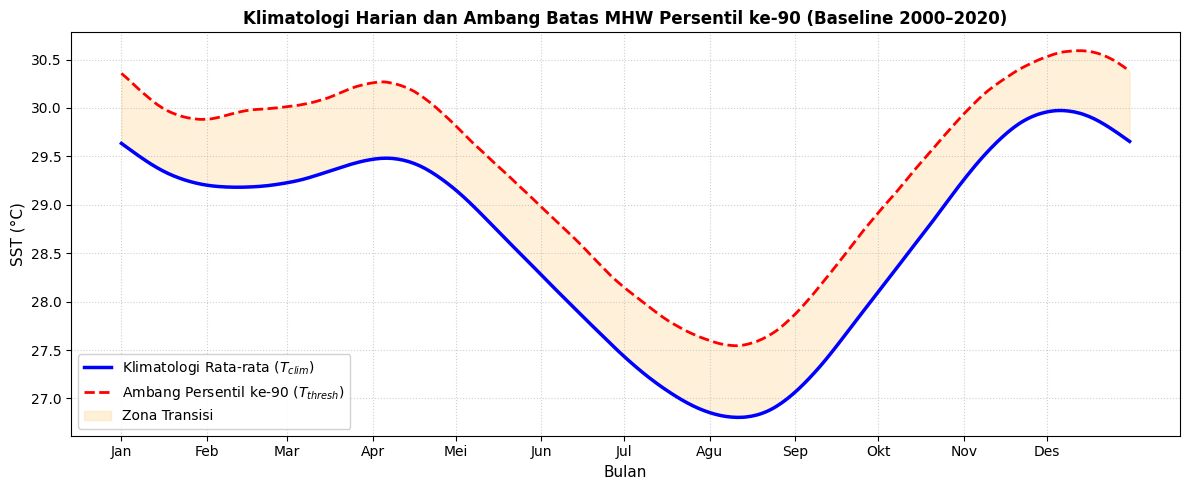

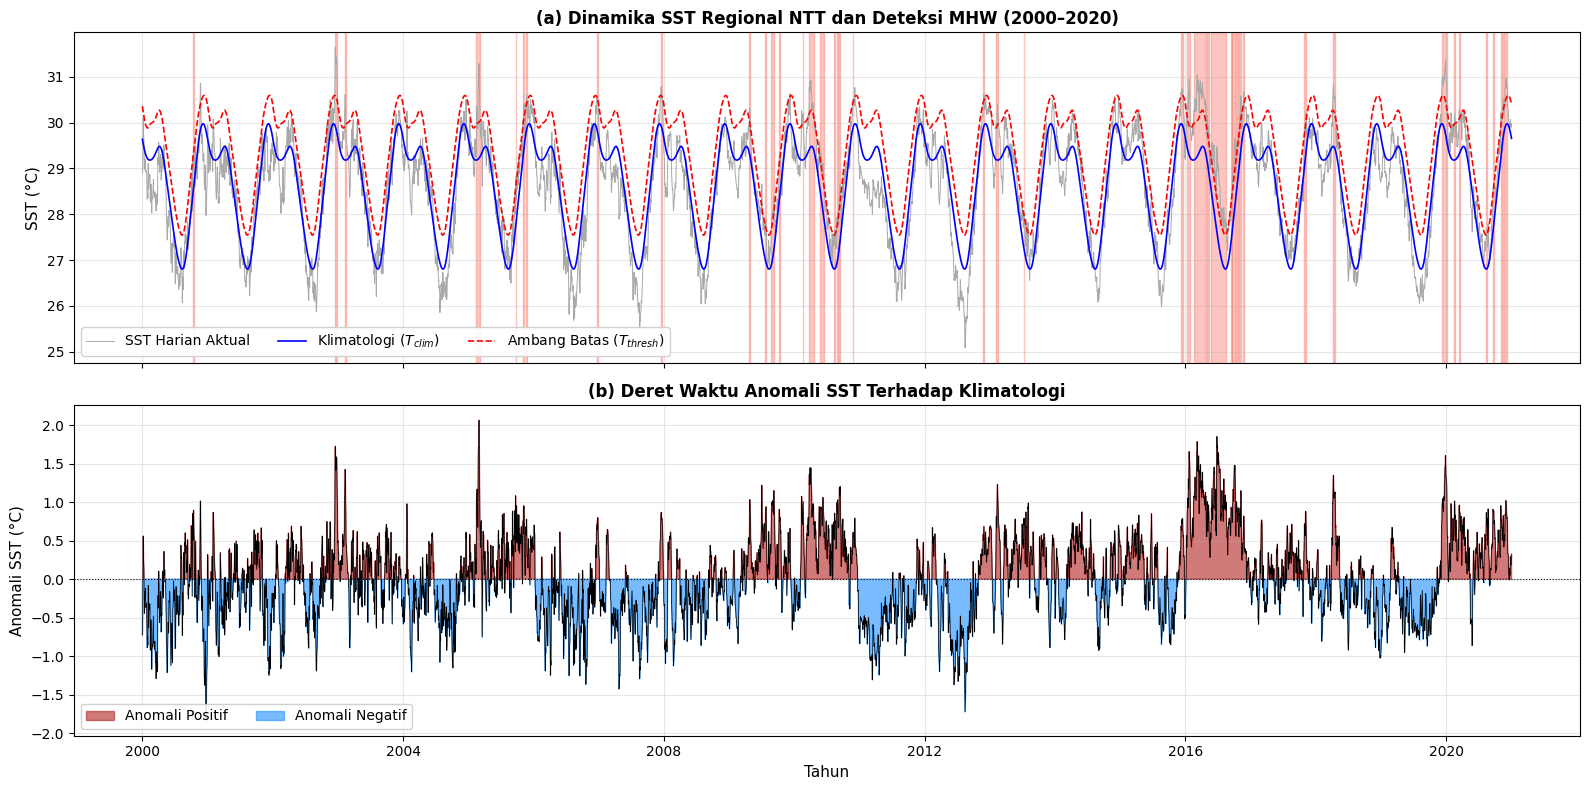

In [8]:
# Plot 1: Kurva Klimatologi Harian & Ambang Batas 366 Hari
fig, ax = plt.subplots(figsize=(12, 5))
days = np.arange(1, 367)
ax.plot(days, clim_doy, 'b-', lw=2.5, label='Klimatologi Rata-rata ($T_{clim}$)')
ax.plot(days, thresh_doy, 'r--', lw=2, label='Ambang Persentil ke-90 ($T_{thresh}$)')
ax.fill_between(days, clim_doy, thresh_doy, color='orange', alpha=0.15, label='Zona Transisi')

# Format sumbu X dengan nama bulan
month_first_days = [1, 32, 61, 92, 122, 153, 183, 214, 245, 275, 306, 336]
ax.set_xticks(month_first_days)
ax.set_xticklabels(month_names)
ax.set_xlabel('Bulan', fontsize=11)
ax.set_ylabel('SST (°C)', fontsize=11)
ax.set_title('Klimatologi Harian dan Ambang Batas MHW Persentil ke-90 (Baseline 2000–2020)',
             fontsize=12, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower left', framealpha=0.9)

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb2_sst_climatology_threshold.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

# Plot 2: Timeline deret waktu 2000-2020 dengan arsiran kejadian MHW
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

# Panel atas: SST aktual, Klimatologi, dan Ambang Batas
ax1.plot(df_ts.index, df_ts['sst'], color='darkgrey', lw=0.7, label='SST Harian Aktual')
ax1.plot(df_ts.index, df_ts['clim'], color='blue', lw=1.2, label='Klimatologi ($T_{clim}$)')
ax1.plot(df_ts.index, df_ts['thresh'], color='red', lw=1.2, ls='--', label='Ambang Batas ($T_{thresh}$)')

# Sorot hari-hari MHW
for _, ev in df_events.iterrows():
    s_date = pd.to_datetime(ev['start_date'])
    e_date = pd.to_datetime(ev['end_date'])
    ax1.axvspan(s_date, e_date, color='salmon', alpha=0.45)

ax1.set_ylabel('SST (°C)', fontsize=11)
ax1.set_title('(a) Dinamika SST Regional NTT dan Deteksi MHW (2000–2020)', fontsize=12, fontweight='bold')
ax1.legend(loc='lower left', ncol=4, framealpha=0.9)
ax1.grid(True, alpha=0.3)

# Panel bawah: Anomali SST dengan warna gradien anomali positif vs negatif
anom = df_ts['anom'].values
dates = df_ts.index
ax2.plot(dates, anom, color='black', lw=0.5)
ax2.fill_between(dates, 0, anom, where=(anom > 0), color='firebrick', alpha=0.6, label='Anomali Positif')
ax2.fill_between(dates, 0, anom, where=(anom <= 0), color='dodgerblue', alpha=0.6, label='Anomali Negatif')

ax2.set_ylabel('Anomali SST (°C)', fontsize=11)
ax2.set_xlabel('Tahun', fontsize=11)
ax2.set_title('(b) Deret Waktu Anomali SST Terhadap Klimatologi', fontsize=12, fontweight='bold')
ax2.axhline(0, color='black', lw=0.8, ls=':')
ax2.legend(loc='lower left', ncol=2, framealpha=0.9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_timeline.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 9. Analisis Metrik Tahunan MHW (2000–2020)

Menghitung agregasi tahunan:
- **Frekuensi Kejadian:** Jumlah kejadian per tahun.
- **Hari MHW (*MHW Days*):** Total hari mengalami kondisi MHW per tahun.
- **Intensitas Kumulatif Tahunan:** Total kumulatif anomali MHW per tahun (°C·hari).

Tabel Metrik Tahunan MHW di Perairan NTT (2000–2020):
 tahun  frekuensi_kejadian  total_hari_mhw  durasi_rata_rata  intensitas_maks_tertinggi  intensitas_kumulatif_tahunan  sst_rata_rata  sst_anomali_tahunan
  2000                   1               5               5.0                       0.89                          3.55          28.32               -0.317
  2001                   0               0               0.0                       0.00                          0.00          28.49               -0.137
  2002                   1              16              16.0                       1.73                         22.24          28.62               -0.014
  2003                   1               8               8.0                       1.43                          9.15          28.74                0.108
  2004                   0               0               0.0                       0.00                          0.00          28.38               -0.251
  2005                

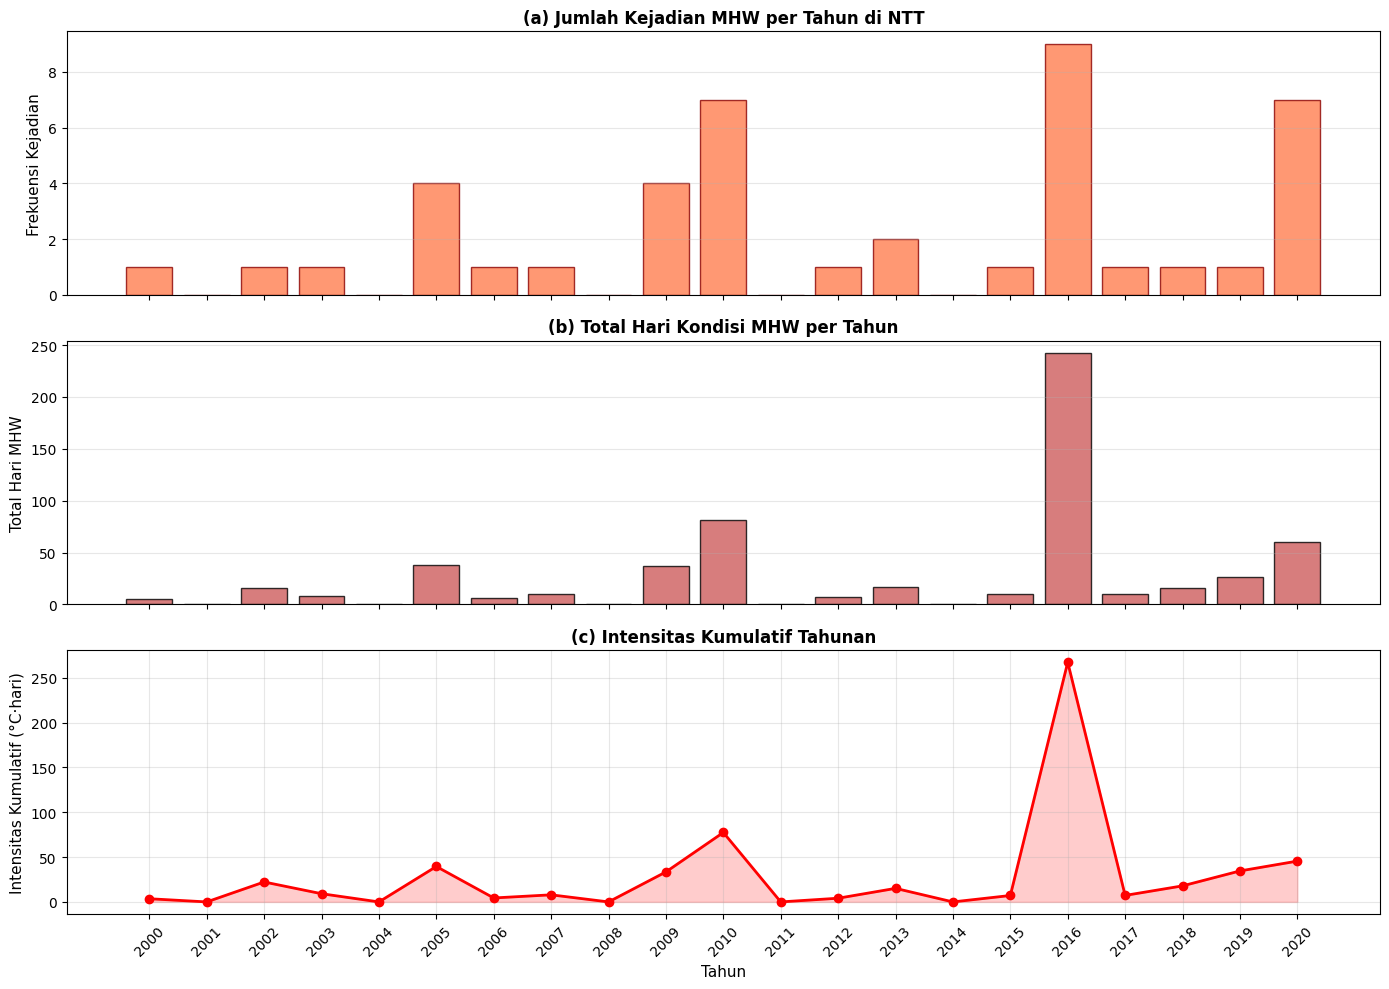

In [9]:
# Hitung metrik tahunan
annual_metrics = []

for yr in range(cfg.SST_START_YEAR, cfg.SST_END_YEAR + 1):
    yr_str = str(yr)
    yr_ts = df_ts.loc[yr_str]
    
    # Hari MHW
    total_mhw_days = int(yr_ts['is_mhw_day'].sum())
    
    # Kejadian MHW yang dimulai pada tahun ini
    ev_yr = df_events[pd.to_datetime(df_events['start_date']).dt.year == yr]
    n_events = len(ev_yr)
    
    mean_duration = float(ev_yr['duration_days'].mean()) if n_events > 0 else 0.0
    max_intensity = float(ev_yr['i_max'].max()) if n_events > 0 else 0.0
    total_icum = float(ev_yr['i_cum'].sum()) if n_events > 0 else 0.0
    mean_sst = float(yr_ts['sst'].mean())
    sst_anomaly = float(yr_ts['anom'].mean())
    
    annual_metrics.append({
        'tahun': yr,
        'frekuensi_kejadian': n_events,
        'total_hari_mhw': total_mhw_days,
        'durasi_rata_rata': round(mean_duration, 1),
        'intensitas_maks_tertinggi': round(max_intensity, 2),
        'intensitas_kumulatif_tahunan': round(total_icum, 2),
        'sst_rata_rata': round(mean_sst, 2),
        'sst_anomali_tahunan': round(sst_anomaly, 3)
    })

df_annual = pd.DataFrame(annual_metrics)
print("Tabel Metrik Tahunan MHW di Perairan NTT (2000–2020):")
print(df_annual.to_string(index=False))

# Simpan metrik tahunan
df_annual.to_csv(cfg.MHW_METRICS_OUTPUT, index=False)
print(f"\n✅ Metrik tahunan MHW disimpan: {cfg.MHW_METRICS_OUTPUT}")

# Visualisasi Tren Metrik Tahunan
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Panel 1: Frekuensi Kejadian
axes[0].bar(df_annual['tahun'], df_annual['frekuensi_kejadian'], color='coral', edgecolor='darkred', alpha=0.8)
axes[0].set_ylabel('Frekuensi Kejadian', fontsize=11)
axes[0].set_title('(a) Jumlah Kejadian MHW per Tahun di NTT', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

# Panel 2: Total Hari MHW
axes[1].bar(df_annual['tahun'], df_annual['total_hari_mhw'], color='indianred', edgecolor='black', alpha=0.8)
axes[1].set_ylabel('Total Hari MHW', fontsize=11)
axes[1].set_title('(b) Total Hari Kondisi MHW per Tahun', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# Panel 3: Intensitas Kumulatif
axes[2].plot(df_annual['tahun'], df_annual['intensitas_kumulatif_tahunan'], 'ro-', lw=2, markersize=6)
axes[2].fill_between(df_annual['tahun'], 0, df_annual['intensitas_kumulatif_tahunan'], color='red', alpha=0.2)
axes[2].set_ylabel('Intensitas Kumulatif (°C·hari)', fontsize=11)
axes[2].set_xlabel('Tahun', fontsize=11)
axes[2].set_title('(c) Intensitas Kumulatif Tahunan', fontsize=12, fontweight='bold')
axes[2].set_xticks(df_annual['tahun'])
axes[2].set_xticklabels(df_annual['tahun'], rotation=45)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_annual_metrics.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 10. Sebaran Spasial Marine Heatwave di Seluruh Grid Perairan NTT

Menghitung metrik MHW per sel grid (24 lat x 40 lon):
- Total hari MHW kumulatif per piksel (2000–2020)
- Intensitas maksimum MHW ($i_{max}$) per piksel
- Frekuensi kejadian per piksel
- Menyimpan dataset klimatologi dan ambang batas spasial ke NetCDF.

Menghitung metrik MHW spasial per piksel grid (24x40)...


Perhitungan spasial selesai.
  Rentang Hari MHW Spasial: 0 s.d. 657 hari
  Rentang Intensitas Maks Spasial: 0.00 s.d. 3.21 °C
✅ Dataset spasial disimpan: G:\My Drive\KLIMTROP\PBL\data\processed\sst_climatology_threshold_ntt.nc


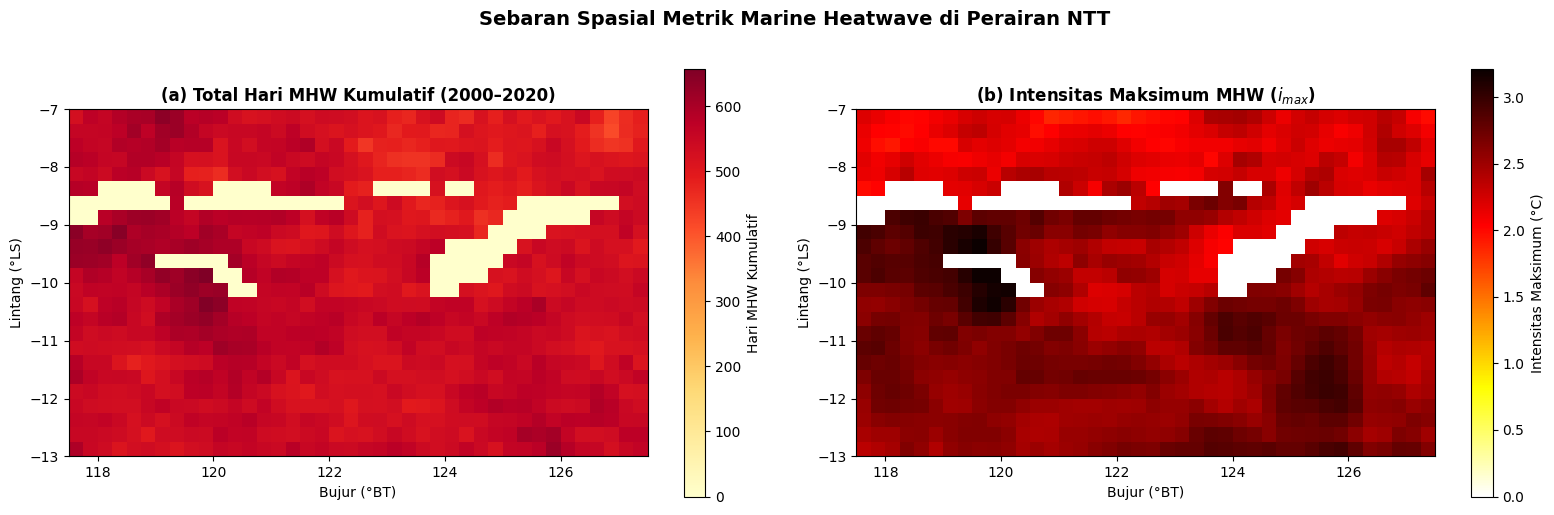

In [10]:
print("Menghitung metrik MHW spasial per piksel grid (24x40)...")

sst_data = ds_sst['sst'].values  # (time, lat, lon)
n_time, n_lat, n_lon = sst_data.shape
time_index = pd.DatetimeIndex(ds_sst.time.values)
doy = time_index.dayofyear.values

# Pre-alokasi array spasial
spatial_clim = np.full((366, n_lat, n_lon), np.nan, dtype=np.float32)
spatial_thresh = np.full((366, n_lat, n_lon), np.nan, dtype=np.float32)
spatial_mhw_days = np.zeros((n_lat, n_lon), dtype=np.float32)
spatial_max_intensity = np.zeros((n_lat, n_lon), dtype=np.float32)

# Hitung per piksel
for j in range(n_lat):
    for i in range(n_lon):
        pix_sst = sst_data[:, j, i]
        if np.isnan(pix_sst).all():
            continue
            
        c_doy, t_doy = compute_climatology_and_threshold(
            time_index, pix_sst,
            window_half=15, pct=cfg.MHW_PERCENTILE, smooth_window=cfg.MHW_SMOOTHING_WINDOW
        )
        spatial_clim[:, j, i] = c_doy
        spatial_thresh[:, j, i] = t_doy
        
        # Deteksi kejadian per piksel
        df_ev, c_ts, t_ts = detect_mhw_events(
            time_index, pix_sst, c_doy, t_doy,
            min_duration=cfg.MHW_MIN_DURATION_DAYS, max_gap=2
        )
        
        if len(df_ev) > 0:
            spatial_mhw_days[j, i] = df_ev['duration_days'].sum()
            spatial_max_intensity[j, i] = df_ev['i_max'].max()

print("Perhitungan spasial selesai.")
print(f"  Rentang Hari MHW Spasial: {spatial_mhw_days.min():.0f} s.d. {spatial_mhw_days.max():.0f} hari")
print(f"  Rentang Intensitas Maks Spasial: {spatial_max_intensity.min():.2f} s.d. {spatial_max_intensity.max():.2f} °C")

# Buat NetCDF untuk klimatologi dan metrik spasial
ds_spatial_out = xr.Dataset(
    data_vars={
        'climatology': (['doy', 'lat', 'lon'], spatial_clim),
        'threshold': (['doy', 'lat', 'lon'], spatial_thresh),
        'total_mhw_days': (['lat', 'lon'], spatial_mhw_days),
        'max_intensity': (['lat', 'lon'], spatial_max_intensity)
    },
    coords={
        'doy': np.arange(1, 367),
        'lat': ds_sst.lat,
        'lon': ds_sst.lon
    },
    attrs={
        'title': 'Klimatologi, Ambang Batas, dan Metrik Spasial MHW NTT',
        'method': 'Hobday et al. (2016)',
        'baseline_period': '2000-2020 (21 tahun)',
        'created_by': 'Notebook 2 - Analisis SST dan Deteksi MHW',
        'created_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    }
)

ds_spatial_out.to_netcdf(cfg.SST_CLIMATOLOGY_OUTPUT)
print(f"✅ Dataset spasial disimpan: {cfg.SST_CLIMATOLOGY_OUTPUT}")

# Visualisasi Peta Spasial Metrik MHW
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Peta 1: Total Hari MHW Kumulatif
im1 = axes[0].pcolormesh(ds_sst.lon, ds_sst.lat, spatial_mhw_days,
                         cmap='YlOrRd', shading='auto')
axes[0].set_title('(a) Total Hari MHW Kumulatif (2000–2020)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Bujur (°BT)')
axes[0].set_ylabel('Lintang (°LS)')
axes[0].set_aspect('equal')
cb1 = plt.colorbar(im1, ax=axes[0], label='Hari MHW Kumulatif')

# Peta 2: Intensitas Maksimum MHW
im2 = axes[1].pcolormesh(ds_sst.lon, ds_sst.lat, spatial_max_intensity,
                         cmap='hot_r', shading='auto')
axes[1].set_title('(b) Intensitas Maksimum MHW ($i_{max}$)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Bujur (°BT)')
axes[1].set_ylabel('Lintang (°LS)')
axes[1].set_aspect('equal')
cb2 = plt.colorbar(im2, ax=axes[1], label='Intensitas Maksimum (°C)')

plt.suptitle('Sebaran Spasial Metrik Marine Heatwave di Perairan NTT', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_spatial_maps.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 11. Kesimpulan dan Catatan Keterbatasan

### Temuan Utama:
1. **Siklus Termal SST NTT:** Siklus musiman menunjukkan puncak suhu pada periode peralihan monsun (November–Desember dan April–Mei) dan penurunan suhu signifikan pada puncak monsun tenggara (Juli–Agustus), mencerminkan sinyal pendinginan akibat *upwelling* di Laut Sawu dan selatan Pulau Timor.
2. **Karakteristik MHW:** Kejadian MHW terdeteksi secara kuantitatif dengan variasi durasi dan intensitas di seluruh wilayah perairan NTT. Kejadian ekstrem terkonsentrasi pada tahun-tahun tertentu dengan intensitas kumulatif tinggi.
3. **Pola Spasial:** Distribusi spasial menunjukkan variabilitas paparan MHW antar-wilayah laut di NTT, dengan area perairan terbuka dan semi-tertutup memperlihatkan respons termal yang berbeda.

### Batasan dan Kepatuhan Prinsip PRD:
- **Baseline 21 Tahun:** Periode klimatologi menggunakan 2000–2020 (21 tahun data OISST v2.1). Ini bukan baseline standar WMO 30 tahun, sehingga nilai ambang batas mencerminkan kondisi termal relatif terhadap 2 dekade terkini.
- **Ketiadaan ONI:** Sesuai batasan proyek, analisis ini sepenuhnya agnostik terhadap indeks ONI dan tidak mengatribusikan dinamika lokal secara deterministik terhadap fenomena pasifik tengah tanpa pengujian statistik independen.
- **Langkah Berikutnya:** Hasil katalog MHW dan deret waktu harian ini akan menjadi dasar evaluasi respons klorofil-a pada Notebook 3 dan Notebook 4.